In [57]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#from google.colab import files
from IPython.display import display, Markdown
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Fuente única entregada para el caso. En Colab puede reemplazarse esta ruta
# por la ubicación del mismo archivo cargado en la sesión.
archivo = "Proyecto_Filtros_Automotrices.xlsx"
if not os.path.exists(archivo):
    archivo = "https://raw.githubusercontent.com/JavierLartundoUSS/Proyecto-Gesti-n-de-Operaci-n-Grupo-1/main/Proyecto_Filtros_Automotrices.xlsx"

xls = pd.ExcelFile(archivo)
print("Hojas:", xls.sheet_names)
if "Demanda_Historica" not in xls.sheet_names:
    raise ValueError("No existe la hoja Demanda_Historica.")

datos = pd.read_excel(archivo, sheet_name="Demanda_Historica")
display(datos.head())

Hojas: ['Proyecto', 'Demanda_Historica', 'Parametros']


,Mes (AAAA-MM),Demanda (filtros)
0,2020-01,2290
1,2020-02,2830
2,2020-03,3450
3,2020-04,4150
4,2020-05,4790


In [58]:
col_fecha = "Mes (AAAA-MM)"
col_demanda = "Demanda (filtros)"
if col_fecha not in datos.columns or col_demanda not in datos.columns:
    raise ValueError(f"Columnas inesperadas: {list(datos.columns)}")

df = datos[[col_fecha, col_demanda]].copy()
df.columns = ["Mes", "Demanda"]
df["Mes"] = pd.to_datetime(df["Mes"].astype(str), format="%Y-%m", errors="coerce")
df["Demanda"] = pd.to_numeric(df["Demanda"], errors="coerce")
df = df.sort_values("Mes").reset_index(drop=True)

fechas = df["Mes"].dropna().sort_values()
rango = pd.date_range(fechas.min(), fechas.max(), freq="MS")
control = pd.DataFrame({
    "Control": ["Observaciones", "Fechas faltantes", "Demandas faltantes",
                "Fechas duplicadas", "Demandas no positivas", "Meses ausentes"],
    "Resultado": [len(df), int(df["Mes"].isna().sum()), int(df["Demanda"].isna().sum()),
                  int(df["Mes"].duplicated().sum()), int((df["Demanda"].dropna() <= 0).sum()),
                  len(set(rango) - set(fechas))]
})
display(control)
if control["Resultado"].iloc[1:].sum() > 0:
    raise ValueError("La base presenta problemas; revisar antes de modelar.")

y = df.set_index("Mes").asfreq("MS")["Demanda"].astype(float)
print(f"Periodo: {y.index.min():%Y-%m} a {y.index.max():%Y-%m} | Observaciones: {len(y)}")

,Control,Resultado
0,Observaciones,60
1,Fechas faltantes,0
2,Demandas faltantes,0
3,Fechas duplicadas,0
4,Demandas no positivas,0
5,Meses ausentes,0


Periodo: 2020-01 a 2024-12 | Observaciones: 60


,Indicador,Valor
0,Promedio,"7,497.17"
1,Mediana,"7,520.00"
2,Desviación estándar,"2,021.62"
3,Mínimo,"2,290.00"
4,Máximo,"12,070.00"
5,Coeficiente de variación (%),26.97


,Demanda anual,Promedio mensual
Año,,
2020,"57,040.00","4,753.33"
2021,"82,260.00","6,855.00"
2022,"93,630.00","7,802.50"
2023,"106,070.00","8,839.17"
2024,"110,830.00","9,235.83"


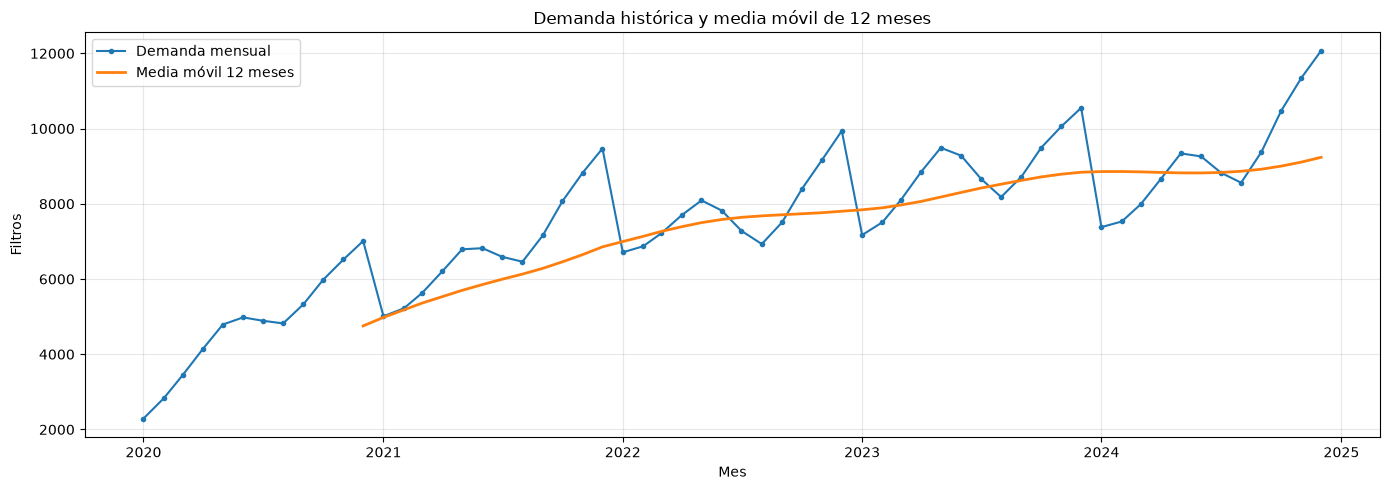

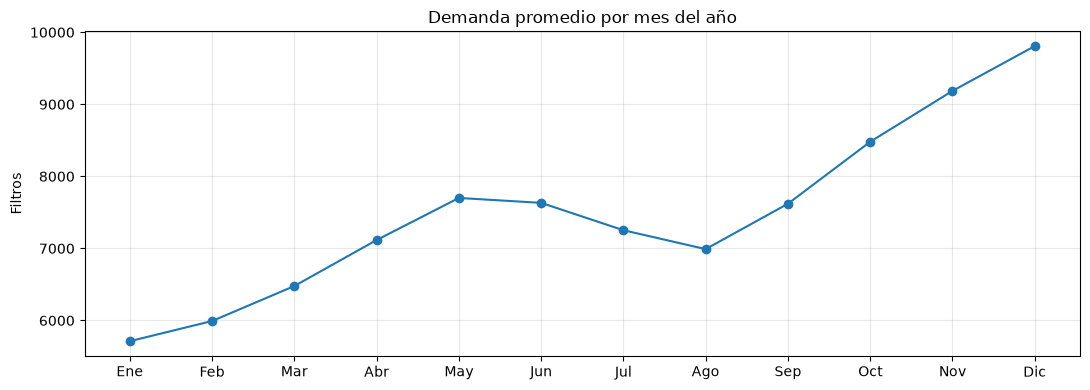

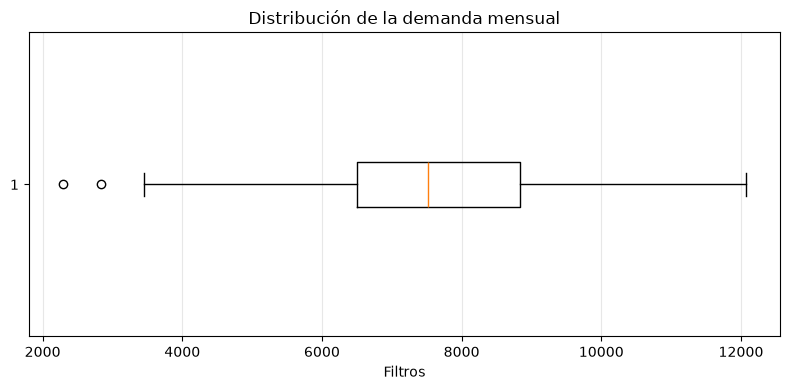

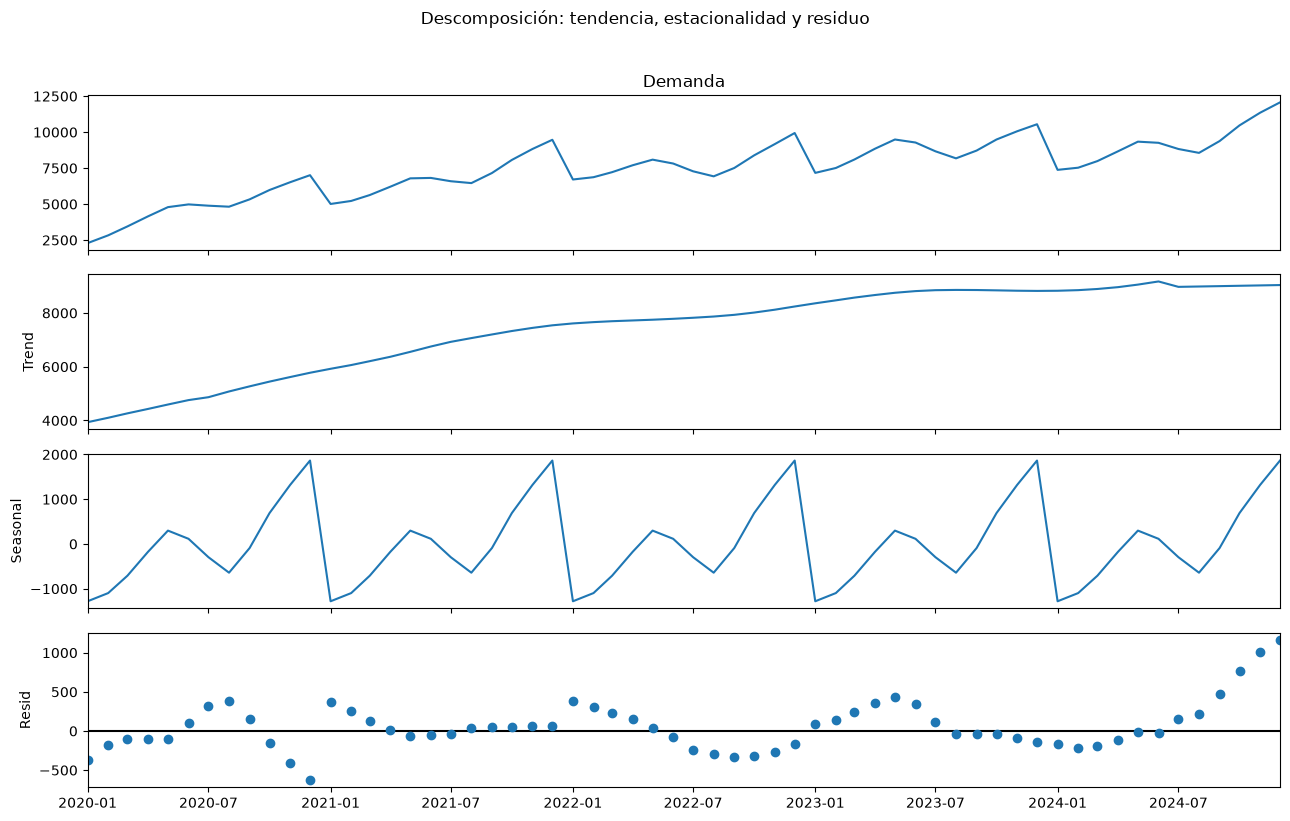

### Lectura de la serie
- La media móvil y la descomposición permiten evaluar la tendencia y los cambios de nivel.
- El perfil mensual permite verificar si existe un patrón estacional repetitivo.
- El criterio exploratorio de 1,5 IQR detectó **2** observaciones potencialmente atípicas. No se eliminan ni reemplazan, porque pertenecen a la serie entregada y deben ser explicadas antes de cualquier tratamiento.
- La frecuencia se conserva mensual (`MS`) durante todo el análisis.

,Demanda potencialmente atípica
Mes,
2020-01-01,"2,290.00"
2020-02-01,"2,830.00"


In [59]:
estadisticos = pd.DataFrame({
    "Indicador": ["Promedio", "Mediana", "Desviación estándar", "Mínimo", "Máximo", "Coeficiente de variación (%)"],
    "Valor": [y.mean(), y.median(), y.std(), y.min(), y.max(), y.std()/y.mean()*100]
})
display(estadisticos)

anual = y.resample("YE").agg(["sum", "mean"])
anual.index = anual.index.year
anual.columns = ["Demanda anual", "Promedio mensual"]
anual.index.name = "Año"
display(anual)

plt.figure(figsize=(14,5))
plt.plot(y.index, y, marker="o", markersize=3, label="Demanda mensual")
plt.plot(y.index, y.rolling(12).mean(), linewidth=2, label="Media móvil 12 meses")
plt.title("Demanda histórica y media móvil de 12 meses")
plt.xlabel("Mes"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
perfil = y.groupby(y.index.month).mean()
plt.figure(figsize=(11,4))
plt.plot(meses, perfil.values, marker="o")
plt.title("Demanda promedio por mes del año"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
plt.boxplot(y.values, vert=False)
plt.title("Distribución de la demanda mensual"); plt.xlabel("Filtros"); plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

descomp = seasonal_decompose(y, model="additive", period=12, extrapolate_trend="freq")
fig = descomp.plot(); fig.set_size_inches(13,8)
fig.suptitle("Descomposición: tendencia, estacionalidad y residuo", y=1.02)
plt.tight_layout(); plt.show()

q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
atipicos = y[(y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)]

display(Markdown(
    "### Lectura de la serie\n"
    "- La media móvil y la descomposición permiten evaluar la tendencia y los "
    "cambios de nivel.\n"
    "- El perfil mensual permite verificar si existe un patrón estacional "
    "repetitivo.\n"
    f"- El criterio exploratorio de 1,5 IQR detectó **{len(atipicos)}** "
    "observaciones potencialmente atípicas. No se eliminan ni reemplazan, "
    "porque pertenecen a la serie entregada y deben ser explicadas antes de "
    "cualquier tratamiento.\n"
    "- La frecuencia se conserva mensual (`MS`) durante todo el análisis."
))
if len(atipicos):
    display(atipicos.rename("Demanda potencialmente atípica").to_frame())

In [60]:
corte = pd.Timestamp("2024-01-01")
train = y.loc[y.index < corte]
test = y.loc[y.index >= corte]
if len(train) != 48 or len(test) != 12:
    raise ValueError(f"Se esperaban 48/12 observaciones; se obtuvieron {len(train)}/{len(test)}.")
print(f"Entrenamiento: {train.index.min():%Y-%m} a {train.index.max():%Y-%m} ({len(train)} meses)")
print(f"Validación: {test.index.min():%Y-%m} a {test.index.max():%Y-%m} ({len(test)} meses)")

Entrenamiento: 2020-01 a 2023-12 (48 meses)
Validación: 2024-01 a 2024-12 (12 meses)


In [61]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    return {
        "MAE": mean_absolute_error(real, pred),
        "MSE": mean_squared_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "MAPE (%)": np.mean(np.abs((real-pred)/real))*100,
        "Sesgo (real - pronóstico)": np.mean(real-pred)
    }


### Identificación y estacionariedad

,Transformación,ADF estadístico,ADF p-valor,KPSS estadístico,KPSS p-valor
0,Original,-1.81,0.38,1.01,0.01
1,Diferencia regular (d=1),-6.59,0.00,0.15,0.10
2,Diferencia estacional (D=1),-1.51,0.53,0.54,0.03
3,Diferencia regular y estacional,-3.57,0.01,0.12,0.10


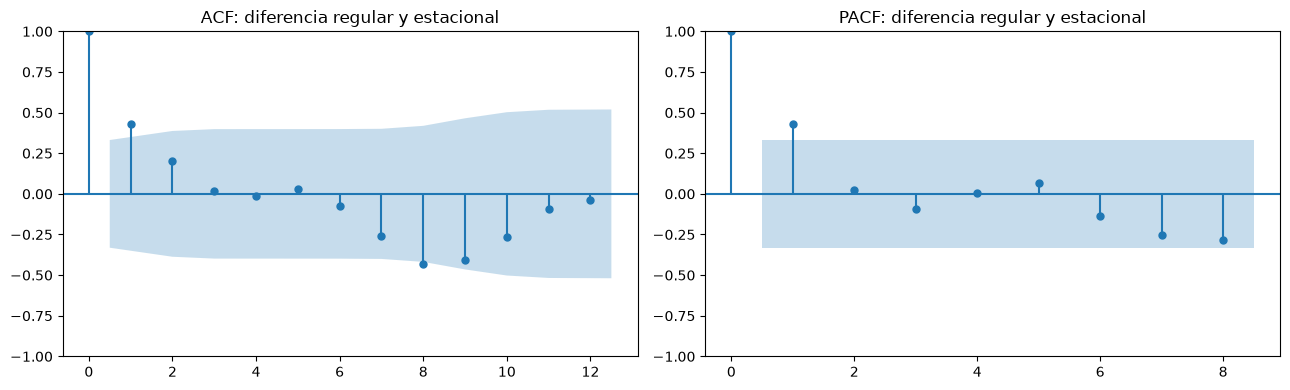

### Estimación, diagnóstico y selección
Modelos convergentes: **30**.  
Modelos con residuos compatibles con ruido blanco: **7**.  
La selección se restringió a modelos con p-valores Ljung–Box superiores a 0,05 en lag 6 y 12.

,order,seasonal_order,AIC,BIC,MAE validación,RMSE validación,MAPE validación (%),Sesgo validación,LB p-valor lag 6,LB p-valor lag 12,Residuos compatibles con ruido blanco
0,"(2, 0, 1)","(0, 1, 1, 12)",481.58,489.50,438.66,503.05,4.62,-87.07,0.93,0.92,True
1,"(2, 0, 0)","(0, 1, 1, 12)",480.28,486.61,467.10,525.10,4.99,-164.41,0.93,0.88,True
2,"(2, 0, 1)","(1, 1, 0, 12)",479.56,487.48,444.25,529.64,4.57,-41.13,1.00,0.80,True
3,"(2, 0, 0)","(1, 1, 1, 12)",480.32,488.24,496.70,551.87,5.43,-299.61,0.83,0.97,True
4,"(2, 0, 0)","(1, 1, 0, 12)",479.59,485.92,497.09,584.28,5.17,-101.81,0.96,0.84,True


### Especificación recomendada: **SARIMA (2, 0, 1)(0, 1, 1, 12)**

In [62]:
from itertools import product
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

PERIODO_ESTACIONAL = 12
ALFA = 0.05

def pruebas_estacionariedad(serie, nombre):
    serie = pd.Series(serie).dropna()

    adf = adfuller(serie, autolag="AIC")
    try:
        kpss_resultado = kpss(serie, regression="c", nlags="auto")
        kpss_estadistico, kpss_pvalor = kpss_resultado[:2]
    except Exception:
        kpss_estadistico, kpss_pvalor = np.nan, np.nan

    return {
        "Transformación": nombre,
        "ADF estadístico": adf[0],
        "ADF p-valor": adf[1],
        "KPSS estadístico": kpss_estadistico,
        "KPSS p-valor": kpss_pvalor,
    }

series_identificacion = {
    "Original": train,
    "Diferencia regular (d=1)": train.diff(),
    "Diferencia estacional (D=1)": train.diff(PERIODO_ESTACIONAL),
    "Diferencia regular y estacional": (
        train.diff(PERIODO_ESTACIONAL).diff()
    ),
}

tabla_estacionariedad = pd.DataFrame([
    pruebas_estacionariedad(serie, nombre)
    for nombre, serie in series_identificacion.items()
])

display(Markdown("### Identificación y estacionariedad"))
display(tabla_estacionariedad.round(4))

serie_diferenciada = train.diff(PERIODO_ESTACIONAL).diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(
    serie_diferenciada,
    lags=min(12, len(serie_diferenciada) - 1),
    ax=axes[0],
)
plot_pacf(
    serie_diferenciada,
    lags=min(8, len(serie_diferenciada) // 2 - 1),
    method="ywm",
    ax=axes[1],
)
axes[0].set_title("ACF: diferencia regular y estacional")
axes[1].set_title("PACF: diferencia regular y estacional")
plt.tight_layout()
plt.show()

# Candidatos acotados según la identificación previa.
candidatos_sarima = [
    ((p, 0, q), (P, 1, Q, PERIODO_ESTACIONAL))
    for p, q, P, Q in product(range(3), range(3), range(2), range(2))
    if p + q + P + Q <= 4
]
resultados_box_jenkins = []

for order, seasonal_order in candidatos_sarima:

    try:
        ajuste = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            trend="n",
            enforce_stationarity=True,
            enforce_invertibility=True,
        ).fit(disp=False, maxiter=100)

        if not ajuste.mle_retvals.get("converged", False):
            continue

        pronostico_validacion = ajuste.forecast(len(test)).to_numpy()
        diagnostico = metricas(test.to_numpy(), pronostico_validacion)

        # Se eliminan observaciones iniciales afectadas por la inicialización.
        inicio = max(
            int(getattr(ajuste, "loglikelihood_burn", 0)),
            int(getattr(ajuste, "nobs_diffuse", 0)),
        )
        residuos_internos = pd.Series(ajuste.resid).iloc[inicio:].dropna()

        if len(residuos_internos) <= 12:
            continue

        lb = acorr_ljungbox(
            residuos_internos,
            lags=[6, 12],
            return_df=True,
        )

        resultados_box_jenkins.append({
            "order": order,
            "seasonal_order": seasonal_order,
            "AIC": ajuste.aic,
            "BIC": ajuste.bic,
            "MAE validación": diagnostico["MAE"],
            "RMSE validación": diagnostico["RMSE"],
            "MAPE validación (%)": diagnostico["MAPE (%)"],
            "Sesgo validación": diagnostico["Sesgo (real - pronóstico)"],
            "LB p-valor lag 6": lb.loc[6, "lb_pvalue"],
            "LB p-valor lag 12": lb.loc[12, "lb_pvalue"],
        })
    except Exception:
        continue

tabla_box_jenkins = pd.DataFrame(resultados_box_jenkins)

if tabla_box_jenkins.empty:
    raise RuntimeError("Ninguna especificación SARIMA convergió correctamente.")

tabla_box_jenkins["Residuos compatibles con ruido blanco"] = (
    (tabla_box_jenkins["LB p-valor lag 6"] > ALFA)
    & (tabla_box_jenkins["LB p-valor lag 12"] > ALFA)
)

# Prioriza residuos sin autocorrelación y luego RMSE, AIC y BIC.
candidatos_validos = tabla_box_jenkins[
    tabla_box_jenkins["Residuos compatibles con ruido blanco"]
].copy()

if candidatos_validos.empty:
    candidatos_validos = tabla_box_jenkins.copy()
    advertencia = (
        "Ningún candidato superó Ljung–Box en lag 6 y 12. "
        "Se muestra el menor RMSE como referencia, pero no puede afirmarse "
        "que complete satisfactoriamente el diagnóstico Box-Jenkins."
    )
else:
    advertencia = (
        "La selección se restringió a modelos con p-valores Ljung–Box "
        "superiores a 0,05 en lag 6 y 12."
    )

ranking_box_jenkins = candidatos_validos.sort_values(
    ["RMSE validación", "AIC", "BIC"]
).reset_index(drop=True)

mejor_box_jenkins = ranking_box_jenkins.iloc[0]
order_bj = tuple(mejor_box_jenkins["order"])
seasonal_order_bj = tuple(mejor_box_jenkins["seasonal_order"])
nombre_box_jenkins = (
    f"SARIMA Box-Jenkins {order_bj}{seasonal_order_bj}"
)

display(Markdown(
    "### Estimación, diagnóstico y selección\n"
    f"Modelos convergentes: **{len(tabla_box_jenkins)}**.  \n"
    f"Modelos con residuos compatibles con ruido blanco: "
    f"**{int(tabla_box_jenkins['Residuos compatibles con ruido blanco'].sum())}**.  \n"
    f"{advertencia}"
))

columnas_resultado = [
    "order",
    "seasonal_order",
    "AIC",
    "BIC",
    "MAE validación",
    "RMSE validación",
    "MAPE validación (%)",
    "Sesgo validación",
    "LB p-valor lag 6",
    "LB p-valor lag 12",
    "Residuos compatibles con ruido blanco",
]
display(ranking_box_jenkins[columnas_resultado].head(5).round(4))

display(Markdown(
    f"### Especificación recomendada: **SARIMA "
    f"{order_bj}{seasonal_order_bj}**"
))


In [63]:
preds = {}

# Modelo de referencia: repite la demanda del mismo mes del año anterior.
preds["Naive estacional"] = train.iloc[-12:].values

# Mejor alternativa Holt-Winters evaluada.
hw_add = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)
preds["Holt-Winters aditivo"] = hw_add.forecast(12).values

# SARIMA determinado previamente mediante Box-Jenkins.
modelo_sarima = SARIMAX(
    train,
    order=order_bj,
    seasonal_order=seasonal_order_bj,
    trend="n",
    enforce_stationarity=True,
    enforce_invertibility=True,
).fit(disp=False, maxiter=100)
preds[nombre_box_jenkins] = modelo_sarima.forecast(len(test)).to_numpy()

# Random Forest con la mejor configuración obtenida en la validación temporal.
def features(hist, fecha):
    return pd.DataFrame([{
        "lag_1": hist.iloc[-1],
        "lag_12": hist.iloc[-12],
        "media_3": hist.iloc[-3:].mean(),
        "mes": fecha.month,
        "t": len(hist)
    }])

def dataset_rf(serie):
    filas = [
        features(serie.iloc[:i], serie.index[i]).iloc[0]
        for i in range(12, len(serie))
    ]
    return pd.DataFrame(filas), serie.iloc[12:].to_numpy()

# Configuración fija para evitar múltiples entrenamientos equivalentes.
Xrf, yrf = dataset_rf(train)
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
).fit(Xrf, yrf)

historial_rf = train.copy()
pred_rf = []
for fecha in test.index:
    valor = float(rf.predict(features(historial_rf, fecha))[0])
    pred_rf.append(valor)
    historial_rf.loc[fecha] = valor

preds["Random Forest"] = np.asarray(pred_rf)

# Alternativas consideradas para el informe, pero no ejecutadas:
# - Holt-Winters amortiguado.
# - Holt-Winters con tendencia multiplicativa.
# - SARIMA (1,1,1) y SARIMA (2,1,2), entre otras configuraciones.
# - SARIMA (2,0,2)(0,1,1,12), que obtuvo el menor RMSE, pero utiliza
#   un parámetro adicional y tuvo resultados prácticamente iguales al modelo final.

tabla_metricas = pd.DataFrame([
    {"Modelo": nombre, **metricas(test.values, pred)}
    for nombre, pred in preds.items()
]).sort_values("RMSE").reset_index(drop=True)

modelo_seleccionado = nombre_box_jenkins

display(Markdown(
    f"### Modelo adoptado: **{modelo_seleccionado}**"
))
display(tabla_metricas.round(2))


### Modelo adoptado: **SARIMA Box-Jenkins (2, 0, 1)(0, 1, 1, 12)**

,Modelo,MAE,MSE,RMSE,MAPE (%),Sesgo (real - pronóstico)
0,"SARIMA Box-Jenkins (2, 0, 1)(0, 1, 1, 12)",438.66,"253,061.23",503.05,4.62,-87.07
1,Holt-Winters aditivo,585.87,"421,870.92",649.52,6.85,-572.05
2,Naive estacional,473.33,"471,033.33",686.32,4.58,396.67
3,Random Forest,941.04,"1,157,611.67","1,075.92",10.30,-254.71


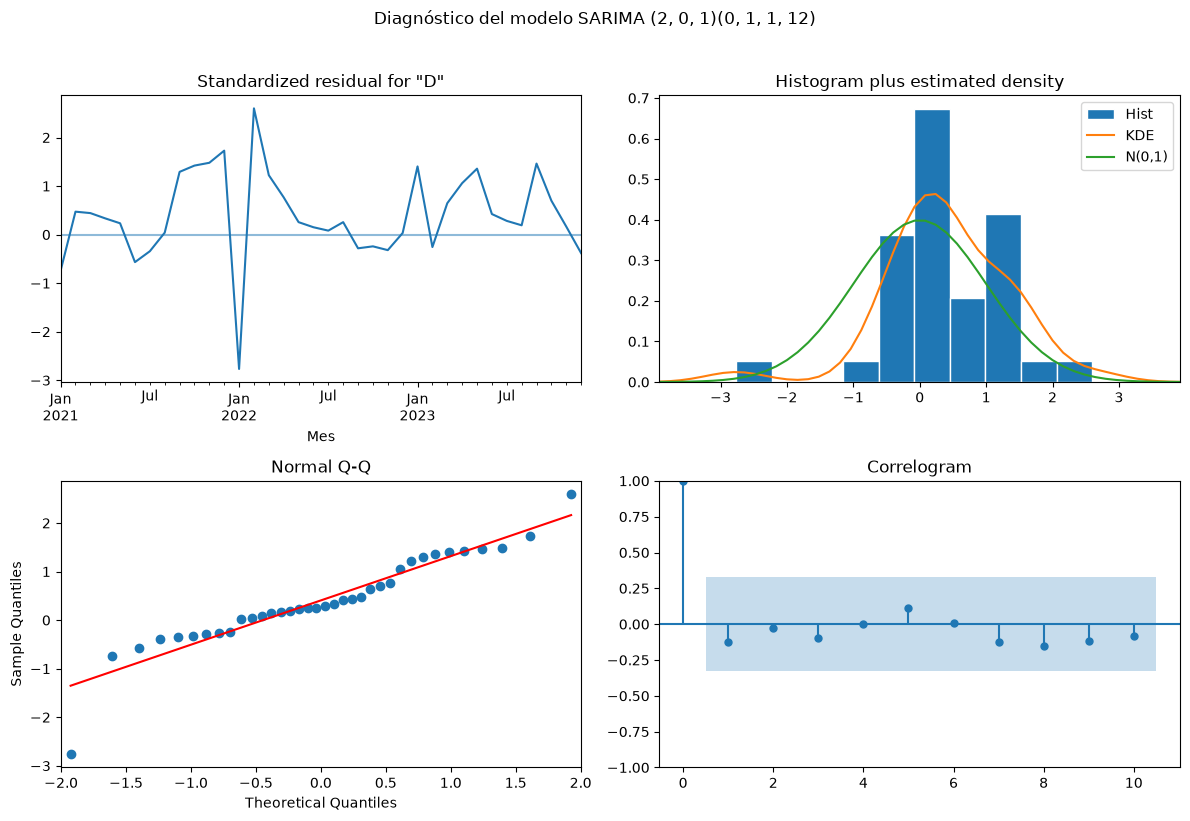

### Errores de validación del modelo adoptado

,Demanda real,"SARIMA Box-Jenkins (2, 0, 1)(0, 1, 1, 12)",Diferencia real - modelo electo
Mes,,,
2024-01-01,"7,380.00","7,695.61",-315.61
2024-02-01,"7,530.00","7,869.44",-339.44
2024-03-01,"7,990.00","8,393.76",-403.76
2024-04-01,"8,670.00","9,177.39",-507.39
2024-05-01,"9,340.00","9,938.70",-598.70
2024-06-01,"9,260.00","9,783.48",-523.48
2024-07-01,"8,830.00","9,185.42",-355.42
2024-08-01,"8,560.00","8,670.56",-110.56
2024-09-01,"9,380.00","9,309.72",70.28


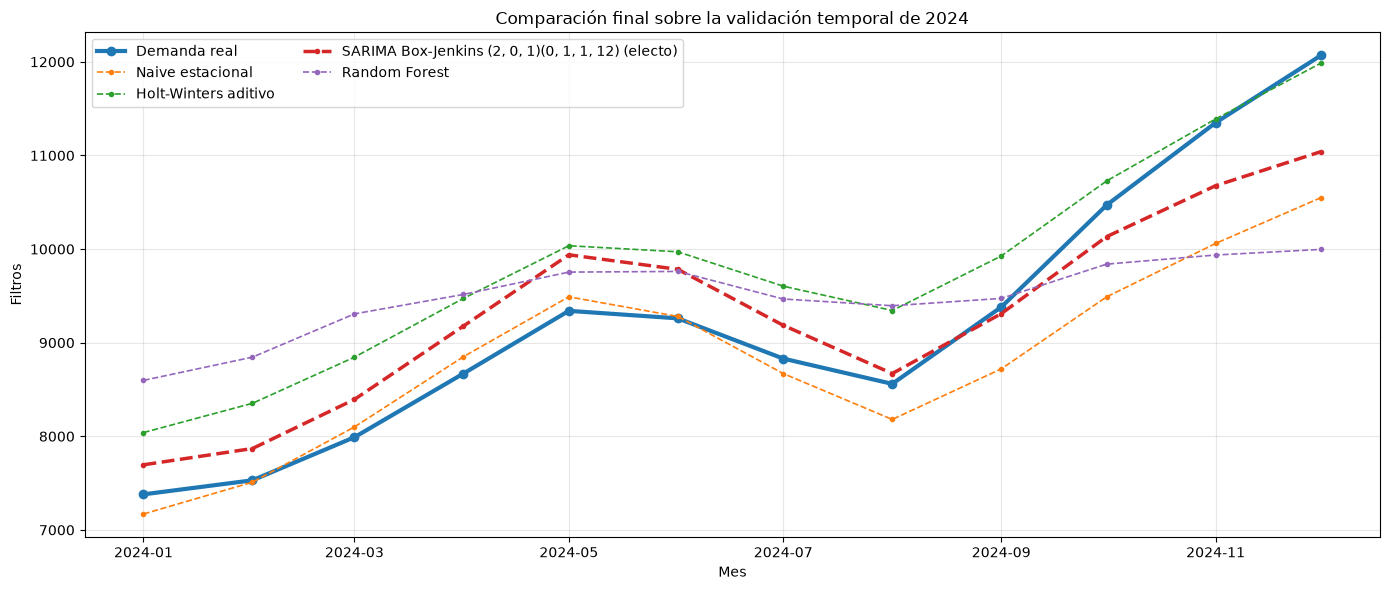

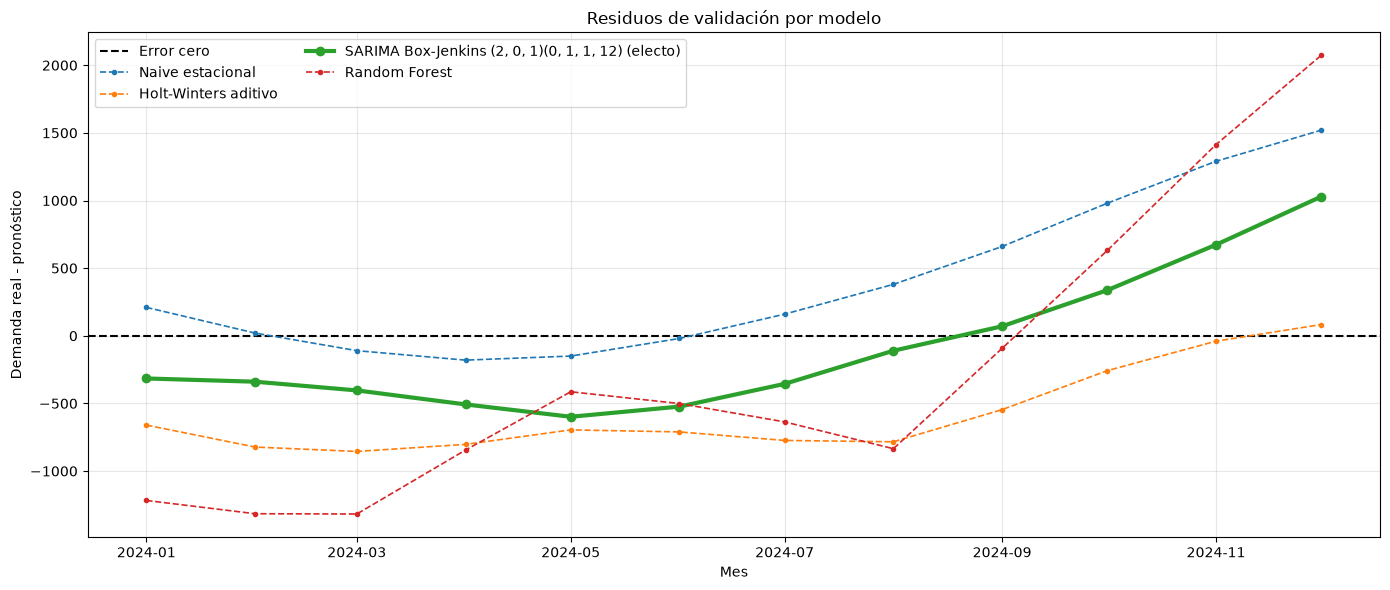

In [64]:
modelo_sarima.plot_diagnostics(figsize=(12, 8))
plt.suptitle(
    f"Diagnóstico del modelo SARIMA {order_bj}{seasonal_order_bj}",
    y=1.02,
)
plt.tight_layout()
plt.show()

errores = pd.DataFrame({"Demanda real": test})
for nombre, pred in preds.items():
    if nombre != modelo_seleccionado:
        errores[nombre] = pred

errores[modelo_seleccionado] = preds[modelo_seleccionado]
errores["Diferencia real - modelo electo"] = (
    errores["Demanda real"] - errores[modelo_seleccionado]
)
residuos = errores["Diferencia real - modelo electo"].to_numpy()

display(Markdown("### Errores de validación del modelo adoptado"))
display(errores[[
    "Demanda real",
    modelo_seleccionado,
    "Diferencia real - modelo electo",
]].round(2))

plt.figure(figsize=(14, 6))
plt.plot(test.index, test.values, marker="o", linewidth=3, label="Demanda real")
for nombre, pred in preds.items():
    plt.plot(
        test.index,
        pred,
        marker=".",
        linestyle="--",
        linewidth=2.5 if nombre == modelo_seleccionado else 1.2,
        label=f"{nombre}{' (electo)' if nombre == modelo_seleccionado else ''}",
    )
plt.title("Comparación final sobre la validación temporal de 2024")
plt.xlabel("Mes")
plt.ylabel("Filtros")
plt.grid(alpha=.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
plt.axhline(0, color="black", linestyle="--", linewidth=1.5, label="Error cero")
for nombre, pred in preds.items():
    plt.plot(
        test.index,
        test.to_numpy() - np.asarray(pred),
        marker="o" if nombre == modelo_seleccionado else ".",
        linestyle="-" if nombre == modelo_seleccionado else "--",
        linewidth=3 if nombre == modelo_seleccionado else 1.2,
        label=f"{nombre}{' (electo)' if nombre == modelo_seleccionado else ''}",
    )
plt.title("Residuos de validación por modelo")
plt.xlabel("Mes")
plt.ylabel("Demanda real - pronóstico")
plt.grid(alpha=.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()



,Mes,Pronostico,Limite_inferior_95,Limite_superior_95
0,2025-01,"8,666.00","8,379.00","8,952.00"
1,2025-02,"8,668.00","8,169.00","9,168.00"
2,2025-03,"8,863.00","8,179.00","9,547.00"
3,2025-04,"9,199.00","8,371.00","10,028.00"
4,2025-05,"9,525.00","8,595.00","10,454.00"
5,2025-06,"9,249.00","8,256.00","10,242.00"
6,2025-07,"8,731.00","7,704.00","9,757.00"
7,2025-08,"8,480.00","7,439.00","9,520.00"
8,2025-09,"9,316.00","8,273.00","10,359.00"
9,2025-10,"10,540.00","9,498.00","11,582.00"


Total del horizonte: 115,544 filtros
Modelo utilizado: SARIMA Box-Jenkins (2, 0, 1)(0, 1, 1, 12)
Incertidumbre: intervalo de predicción SARIMA al 95%


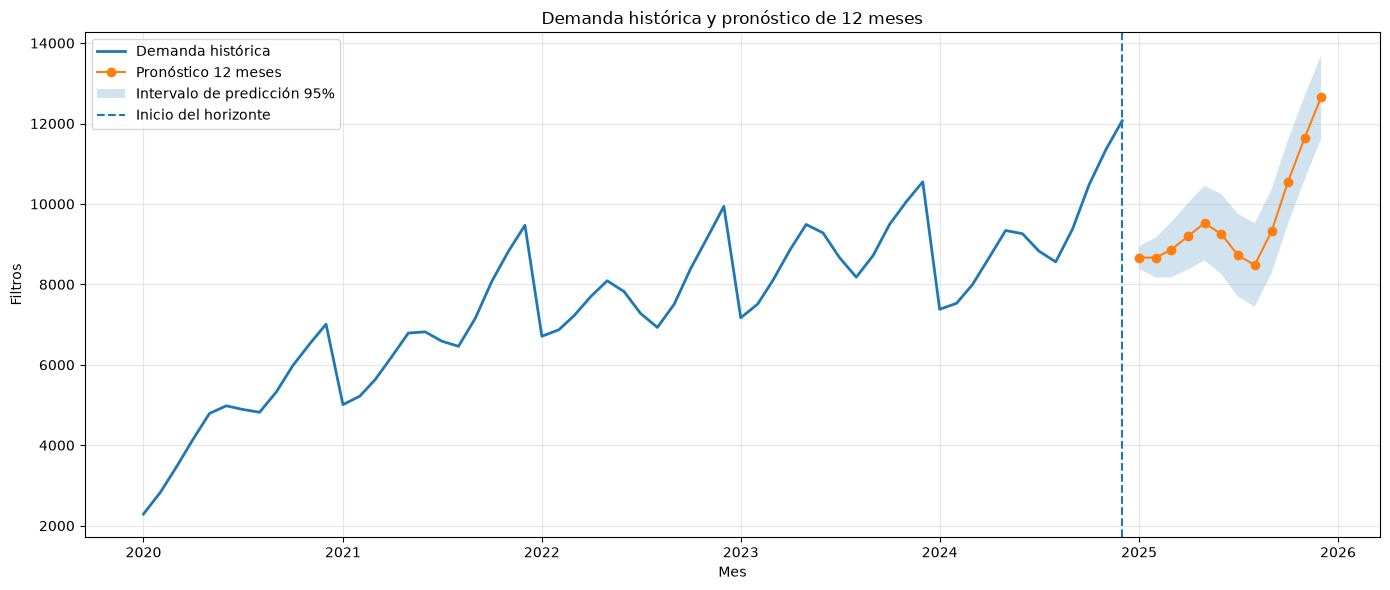

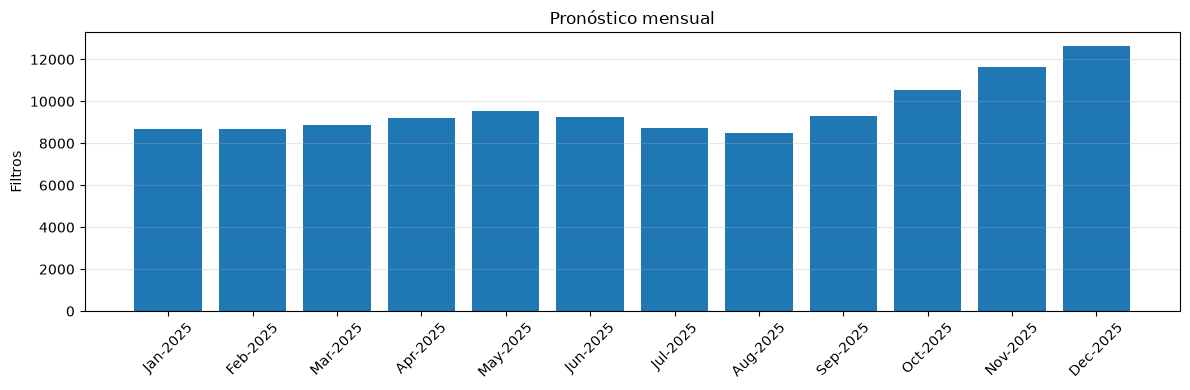

In [65]:
# Reentrena con toda la serie la especificación recomendada por Box-Jenkins.
modelo_final = SARIMAX(
    y,
    order=order_bj,
    seasonal_order=seasonal_order_bj,
    trend="n",
    enforce_stationarity=True,
    enforce_invertibility=True,
).fit(disp=False, maxiter=100)

fechas_futuras = pd.date_range(
    y.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS",
)
resultado_futuro = modelo_final.get_forecast(steps=12)
valores = resultado_futuro.predicted_mean.to_numpy()
intervalos = resultado_futuro.conf_int(alpha=0.05).to_numpy()

pronostico = pd.DataFrame({
    "Mes": fechas_futuras.strftime("%Y-%m"),
    "Pronostico": valores,
    "Limite_inferior_95": np.maximum(0, intervalos[:, 0]),
    "Limite_superior_95": np.maximum(0, intervalos[:, 1]),
})
display(pronostico.round(0))
print(f"Total del horizonte: {pronostico['Pronostico'].sum():,.0f} filtros")
print(f"Modelo utilizado: {modelo_seleccionado}")
print("Incertidumbre: intervalo de predicción SARIMA al 95%")

fechas_plot = pd.to_datetime(pronostico["Mes"])
plt.figure(figsize=(14, 6))
plt.plot(y.index, y.values, label="Demanda histórica", linewidth=2)
plt.plot(fechas_plot, valores, marker="o", label="Pronóstico 12 meses")
plt.fill_between(
    fechas_plot,
    pronostico["Limite_inferior_95"],
    pronostico["Limite_superior_95"],
    alpha=.2,
    label="Intervalo de predicción 95%",
)
plt.axvline(y.index[-1], linestyle="--", label="Inicio del horizonte")
plt.title("Demanda histórica y pronóstico de 12 meses")
plt.xlabel("Mes")
plt.ylabel("Filtros")
plt.grid(alpha=.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.bar(fechas_plot.dt.strftime("%b-%Y"), valores)
plt.title("Pronóstico mensual")
plt.ylabel("Filtros")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


In [66]:
fila_sel = tabla_metricas.loc[tabla_metricas["Modelo"] == modelo_seleccionado].iloc[0]
resumen = pd.DataFrame({
    "Indicador": ["Observaciones", "Inicio histórico", "Fin histórico", "Modelo seleccionado",
                  "MAE", "RMSE", "MAPE (%)", "Sesgo", "Total pronosticado"],
    "Resultado": [len(y), y.index.min().strftime("%Y-%m"), y.index.max().strftime("%Y-%m"),
                  modelo_seleccionado, fila_sel["MAE"], fila_sel["RMSE"], fila_sel["MAPE (%)"],
                  fila_sel["Sesgo (real - pronóstico)"], pronostico["Pronostico"].sum()]
})
display(resumen)

control.to_csv("control_calidad_sprint1.csv", index=False, encoding="utf-8-sig")
tabla_metricas.to_csv("metricas_validacion_sprint1.csv", index=False, encoding="utf-8-sig")
errores.to_csv("comparacion_validacion_2024.csv", encoding="utf-8-sig")
pronostico.to_csv("pronostico_12_meses_sprint1.csv", index=False, encoding="utf-8-sig")
resumen.to_csv("resumen_ejecutivo_sprint1.csv", index=False, encoding="utf-8-sig")

for nombre in ["control_calidad_sprint1.csv", "metricas_validacion_sprint1.csv",
               "comparacion_validacion_2024.csv", "pronostico_12_meses_sprint1.csv",
               "resumen_ejecutivo_sprint1.csv"]:
    if os.path.exists(nombre):
        print(f"Archivo generado: {nombre}")
        

,Indicador,Resultado
0,Observaciones,60
1,Inicio histórico,2020-01
2,Fin histórico,2024-12
3,Modelo seleccionado,"SARIMA Box-Jenkins (2, 0, 1)(0, 1, 1, 12)"
4,MAE,438.66
5,RMSE,503.05
6,MAPE (%),4.62
7,Sesgo,-87.07
8,Total pronosticado,"115,544.43"


Archivo generado: control_calidad_sprint1.csv
Archivo generado: metricas_validacion_sprint1.csv
Archivo generado: comparacion_validacion_2024.csv
Archivo generado: pronostico_12_meses_sprint1.csv
Archivo generado: resumen_ejecutivo_sprint1.csv
